<a href="https://colab.research.google.com/github/muralisagili007-del/EDA-PROJECT/blob/main/boosting_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np

import pandas as pd

import seaborn as sns

import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('/content/heart.csv')

In [ ]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [ ]:
df.duplicated().sum()

np.int64(723)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [ ]:
# Outlier treatment

num_col = df.select_dtypes(include=np.number).columns

print(num_col)

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')


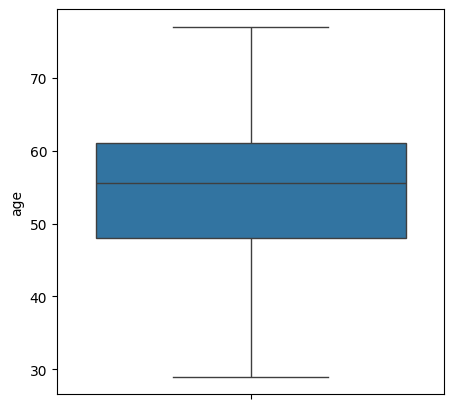

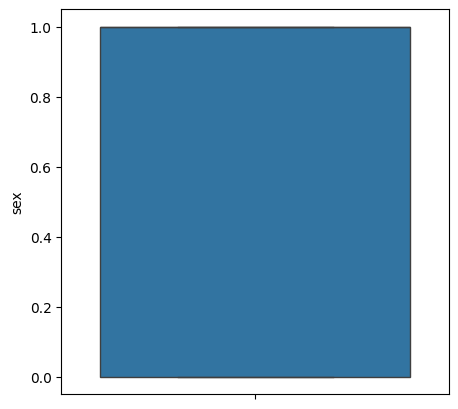

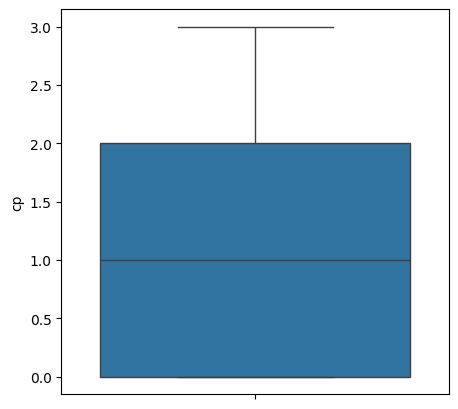

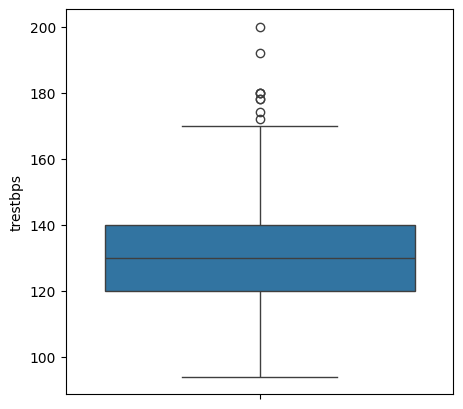

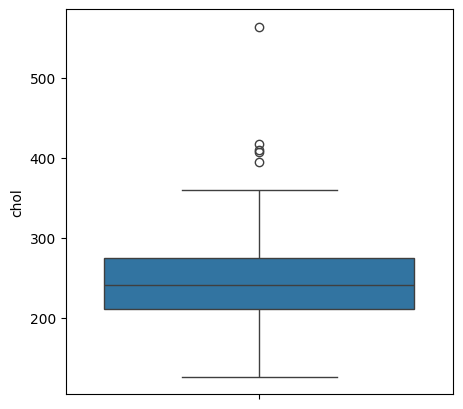

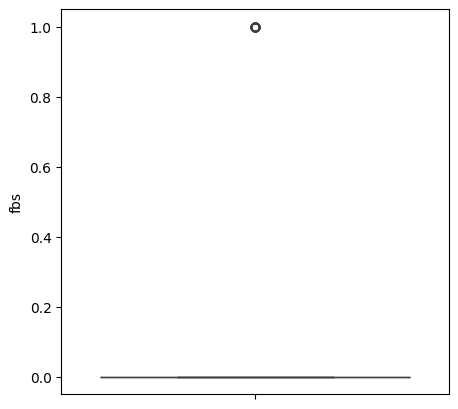

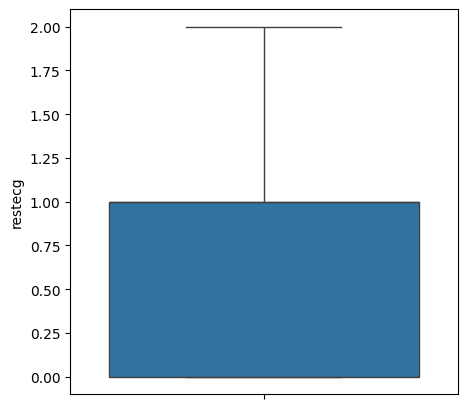

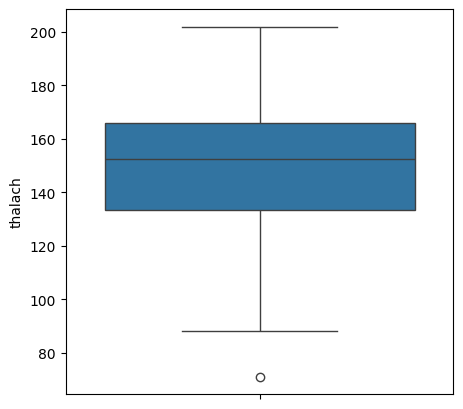

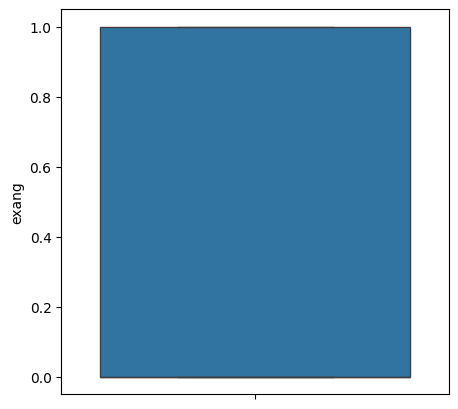

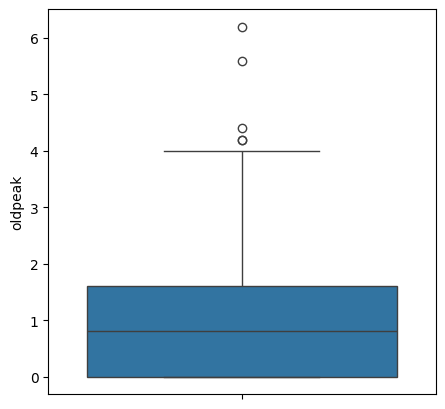

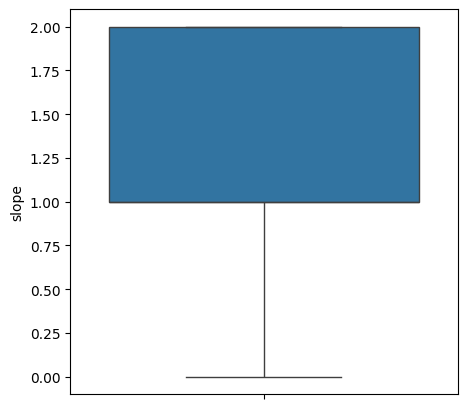

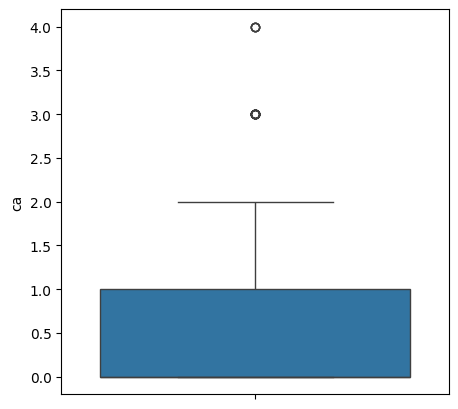

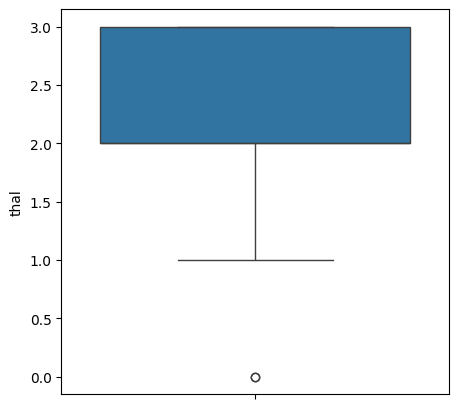

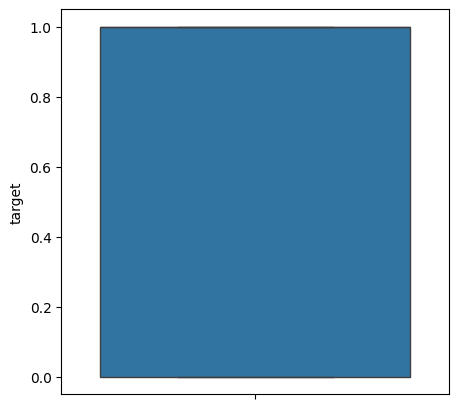

In [ ]:
for col in num_col:

  plt.figure(figsize=(5,5))

  sns.boxplot(df[col])

  plt.show()

In [ ]:
for col in num_col:

  Q1 = df[col].quantile(0.25)

  Q3 = df[col].quantile(0.75)

  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR

  upper_bound = Q3 + 1.5 * IQR

  df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

  print(f"Outliers in {col} removed")

Outliers in age removed
Outliers in sex removed
Outliers in cp removed
Outliers in trestbps removed
Outliers in chol removed
Outliers in fbs removed
Outliers in restecg removed
Outliers in thalach removed
Outliers in exang removed
Outliers in oldpeak removed
Outliers in slope removed
Outliers in ca removed
Outliers in thal removed
Outliers in target removed


In [ ]:
# Outlier treatment

num_col = df.select_dtypes(include=np.number).columns.drop('target')

print(num_col)

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal'],
      dtype='object')


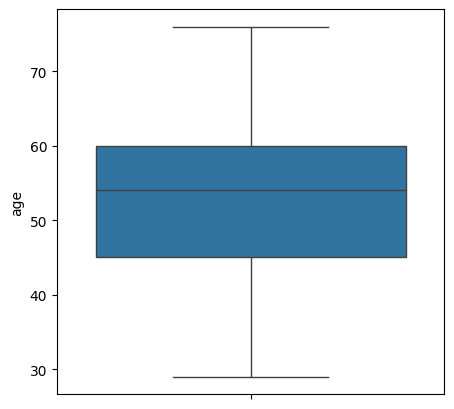

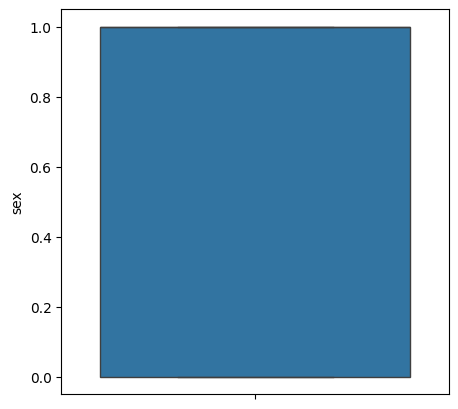

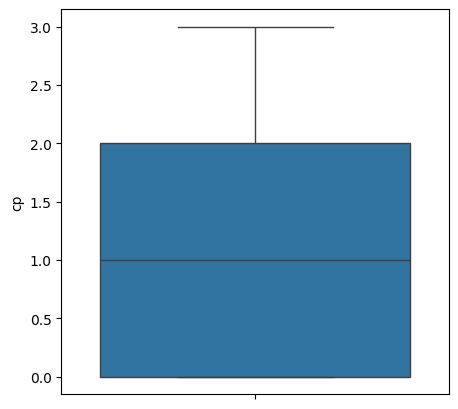

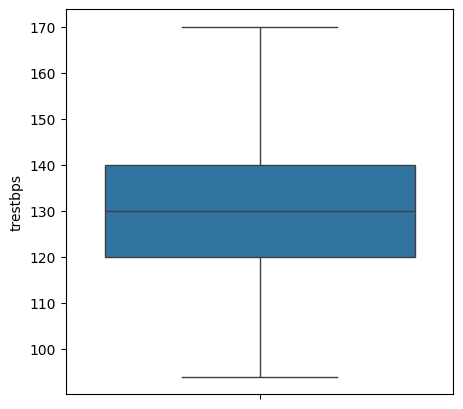

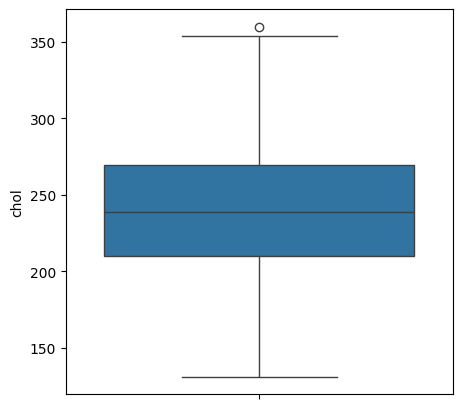

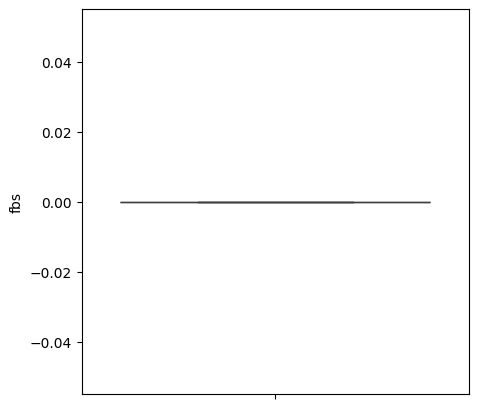

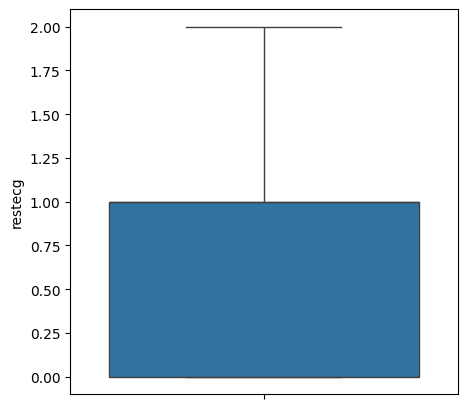

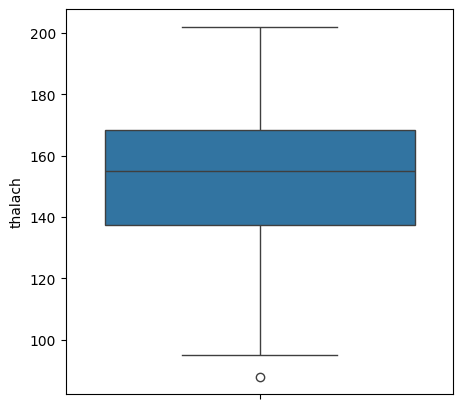

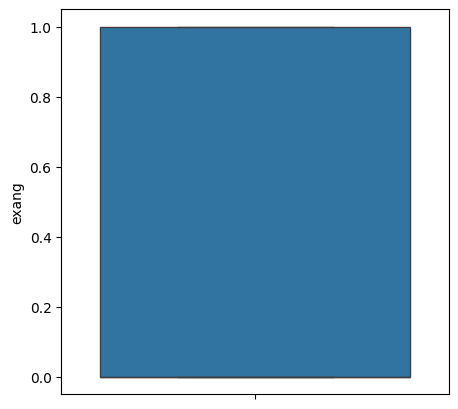

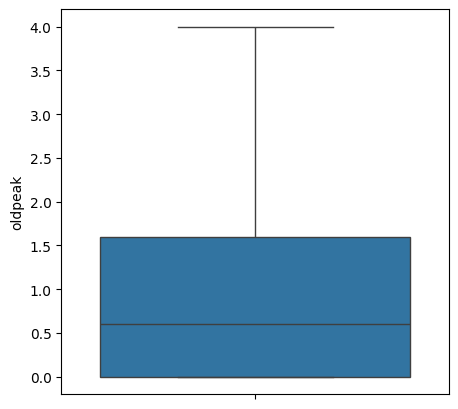

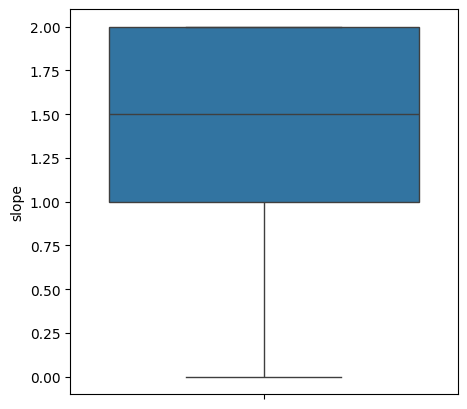

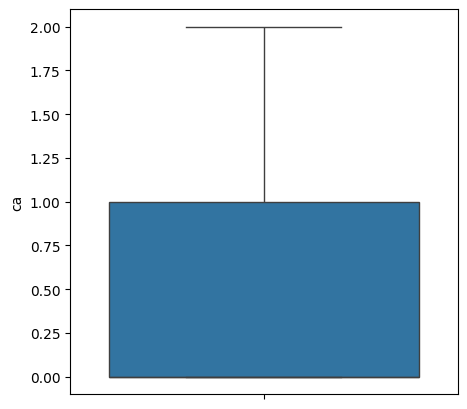

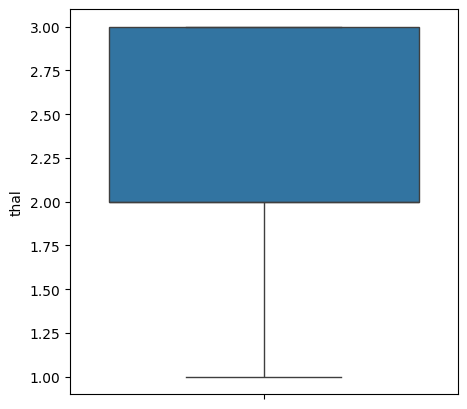

In [ ]:
for col in num_col:

  plt.figure(figsize=(5,5))

  sns.boxplot(df[col])

  plt.show()

In [ ]:
for col in num_col:

  Q1 = df[col].quantile(0.25)

  Q3 = df[col].quantile(0.75)

  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR

  upper_bound = Q3 + 1.5 * IQR

  df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

  print(f"Outliers in {col} removed")

Outliers in age removed
Outliers in sex removed
Outliers in cp removed
Outliers in trestbps removed
Outliers in chol removed
Outliers in fbs removed
Outliers in restecg removed
Outliers in thalach removed
Outliers in exang removed
Outliers in oldpeak removed
Outliers in slope removed
Outliers in ca removed
Outliers in thal removed


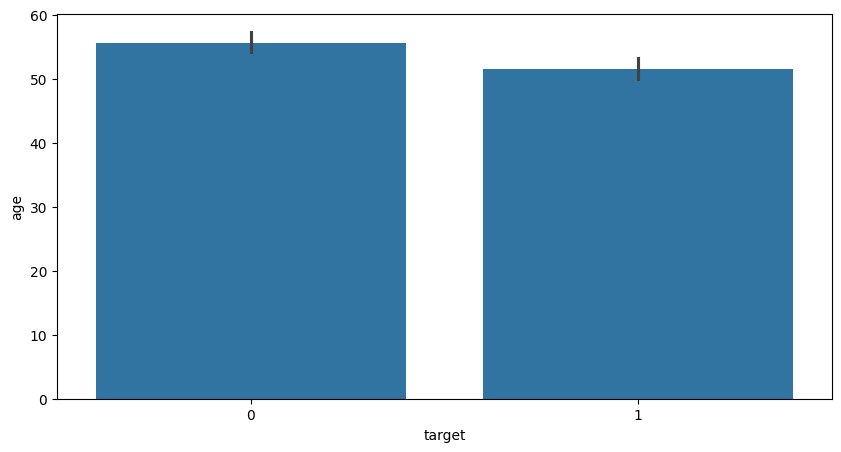

In [ ]:
# Bivariate

#Age vs H.D

plt.figure(figsize=(10,5))

sns.barplot(x='target',y='age',data=df)

plt.show()

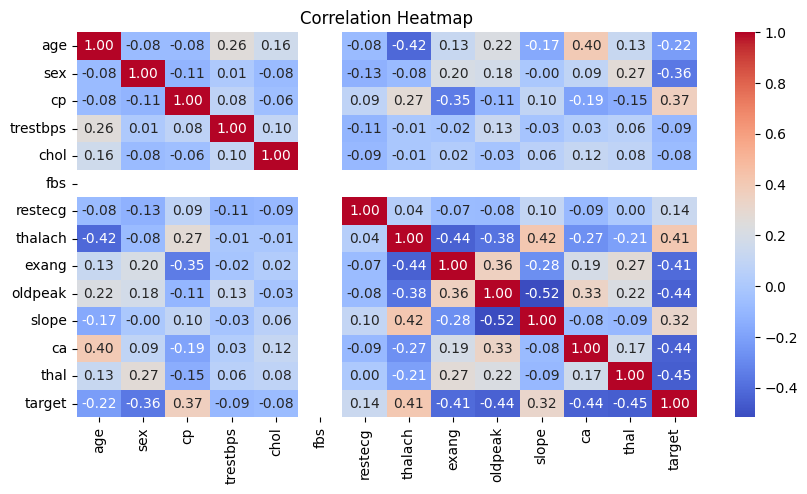

In [ ]:
# /multi variate Analysis

plt.figure(figsize=(10,5))

sns.heatmap(df.select_dtypes(include = 'number').corr(),annot = True, cmap = "coolwarm", fmt = '.2f')

plt.title('Correlation Heatmap')

plt.show()

In [ ]:
# converting the object data type into numerica

cat_col = df.select_dtypes(include='object').columns

print(cat_col)

Index([], dtype='object')


In [ ]:
for col in cat_col:

  print(col, df[col].unique())

In [ ]:
# convert

df = pd.get_dummies(df, columns=cat_col, drop_first=True, dtype = int)

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
5,58,0,0,100,248,0,0,122,0,1.0,1,0,2,1
7,55,1,0,160,289,0,0,145,1,0.8,1,1,3,0


In [ ]:
# convert only the columns that are still present in df
cols_to_convert = [col for col in cat_col if col in df.columns]

if cols_to_convert:
    df = pd.get_dummies(df, columns=cols_to_convert, drop_first=True, dtype=int)

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
5,58,0,0,100,248,0,0,122,0,1.0,1,0,2,1
7,55,1,0,160,289,0,0,145,1,0.8,1,1,3,0


In [ ]:
# Separate X, y

X = df.drop('target', axis=1)

y = df['target']

In [ ]:
print(X.shape)

print(y.shape)

(226, 13)
(226,)


In [ ]:
# Model

from sklearn .ensemble import AdaBoostClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, GradientBoostingClassifier

In [ ]:
model = AdaBoostClassifier(

    n_estimators=100,

    random_state=42,

    learning_rate = 1.0

)

In [ ]:
# Model

from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Train (fit) the AdaBoost model
model.fit(X_train, y_train)

# 3. Predict on the test set
y_pred = model.predict(X_test)
print("Predictions:", y_pred)

Predictions: [1 0 1 1 1 0 0 1 1 0 1 1 0 1 1 0 1 1 0 0 1 1 0 1 1 0 1 1 1 0 0 0 1 0 1 1 1
 0 1 1 0 1 1 0 0 0]


In [ ]:
y_pred = model.predict(X_test)

print(y_pred)

[1 0 1 1 1 0 0 1 1 0 1 1 0 1 1 0 1 1 0 0 1 1 0 1 1 0 1 1 1 0 0 0 1 0 1 1 1
 0 1 1 0 1 1 0 0 0]


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Python

print("Training accuracy:", model.score(X_train, y_train))

print("Testing accuracy:", model.score(X_test, y_test))

Training accuracy: 0.9611111111111111
Testing accuracy: 0.8043478260869565


In [ ]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

In [ ]:
print("Training accuracy:", rf.score(X_train, y_train))

print("Testing accuracy:", rf.score(X_test, y_test))

Training accuracy: 1.0
Testing accuracy: 0.782608695652174


In [ ]:
# Hyper parameter tuning

import pandas as pd
import numpy as np
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.ensemble import RandomForestClassifier

# Ensure data preprocessing and splitting are completed
# Loading and cleaning duplicates
df = pd.read_csv('/content/heart.csv')
df.drop_duplicates(inplace=True)

# Outlier removal
num_col = df.select_dtypes(include=np.number).columns.drop('target')
for col in num_col:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

# One-Hot Encoding categorical variables
cat_col = df.select_dtypes(include='object').columns
df = pd.get_dummies(df, columns=cat_col, drop_first=True, dtype=int)

# Split features and target
X = df.drop('target', axis=1)
y = df['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the estimator
rf = RandomForestClassifier(random_state=42)

param_grid = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5, scoring='accuracy')

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [None, 10, 20, 30],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [50, 100, 200, 300]},
             scoring='accuracy')